<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

# <span id="chapter1" style="color:#89AC76;">1. Imports</span>

<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from functools import partial # pass a pre-applied selector via functools.partial.
from copy import deepcopy

from scripts.triangle_sol import TriangleSolution, AdaptiveMutationRateTriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga_utils import get_fitness
from scripts.experiments import plot_fitness_history
from scripts.new_hill_climbing import hill_climbing, plot_hill_climbing_log
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    geometric_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
    geometric_mutation,
    # new fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity,
    AutomaticFitnessSharingSelection,
    AdvancedFitnessSharingSelection,
    GenerationCounterCallback,
    population_diversity_report
)
from scripts.statistical_comparison import (
    run_ga_statistical_comparison,
    plot_statistical_comparison,
    run_statistical_test,
    save_statistical_results,
    load_statistical_results,
    plot_statistical_comparison_interactive
)

# <span id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</span>

<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


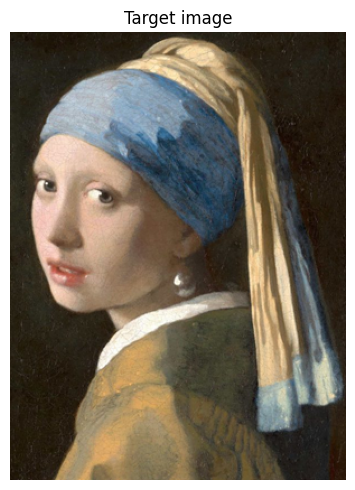

In [2]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.float32)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Pass the target to TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr

plt.figure(figsize=(4, 5))
plt.imshow(target_arr / 255)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

# <span id="chapter3" style="color:#89AC76;">3. Solution Representation</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)

In [4]:
sol = TriangleSolution()

In [5]:
sol = TriangleSolution()
sol.representation

array([ 39.,  15., 226., 385., 166.,  62., 207., 199.,  55., 144., 110.,
       163., 221., 143.,  28., 258.,  67.,  73., 219., 185.,  45., 190.,
       230., 234., 292., 257., 210., 156., 209.,  71., 138., 166., 138.,
       374.,  42., 210., 158.,  77., 252.,  79., 103., 213., 118., 227.,
       168., 100.,  18., 170., 228., 112.,  12., 175., 227., 301.,  65.,
       228., 216., 152.,  94.,  20.,  17., 266.,  39., 344., 234., 397.,
       166., 198., 160., 157.,  59.,   6.,  96., 282., 163., 387., 175.,
       105., 249., 160., 161., 104.,  97.,  74., 210., 302.,  89., 217.,
        87.,  20.,   8., 238., 266., 262., 184., 219.,  28., 110., 216.,
       228., 279., 294., 140., 105.,  67., 147., 228., 118., 137.,  79.,
       257., 370., 213., 257.,   3., 235.,  33., 185., 117., 191.,  41.,
       365.,  63., 182., 168., 343.,  86., 187.,  23., 206.,  16., 270.,
       211., 127.,  49., 331.,  48., 147., 107., 132.,  28., 265., 284.,
       109.,  91., 290., 183., 186., 123.,  81., 25

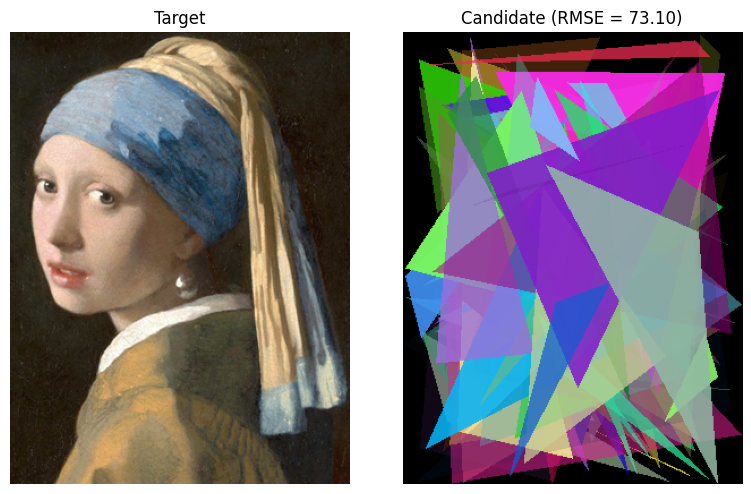

In [6]:
sol.show()

The output generated is a **single random individual**.

# <span id="chapter4" style="color:#89AC76;">4. Baseline GA Run</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [3]:
best_sol, history, avg_history = genetic_algorithm(
    population_size = 50,
    n_generations = 200,
    selection_function = tournament_selection,
    crossover_function = one_point_crossover,
    mutation_function = triangle_gaussian_mutation,
    crossover_rate = 0.9,
    mutation_rate = 0.02,
    mutation_rate_decay = None,
    elitism_n = 2,
    n_jobs = -1,
    verbose = True,
    verbose_every = 25
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 61.4989 | avg RMSE: 66.7370 | mut rate: 0.02000
Gen   25 | best RMSE: 51.8284 | avg RMSE: 52.2657 | mut rate: 0.02000
Gen   50 | best RMSE: 49.2519 | avg RMSE: 49.6504 | mut rate: 0.02000
Gen   75 | best RMSE: 47.4375 | avg RMSE: 47.7246 | mut rate: 0.02000
Gen  100 | best RMSE: 45.7331 | avg RMSE: 45.9751 | mut rate: 0.02000
Gen  125 | best RMSE: 44.3684 | avg RMSE: 44.6198 | mut rate: 0.02000
Gen  150 | best RMSE: 42.8598 | avg RMSE: 43.2923 | mut rate: 0.02000
Gen  175 | best RMSE: 41.8822 | avg RMSE: 42.0743 | mut rate: 0.02000
Gen  199 | best RMSE: 40.9549 | avg RMSE: 41.1617 | mut rate: 0.02000

Finished. Best RMSE: 40.9549
Best RMSE : 40.9549


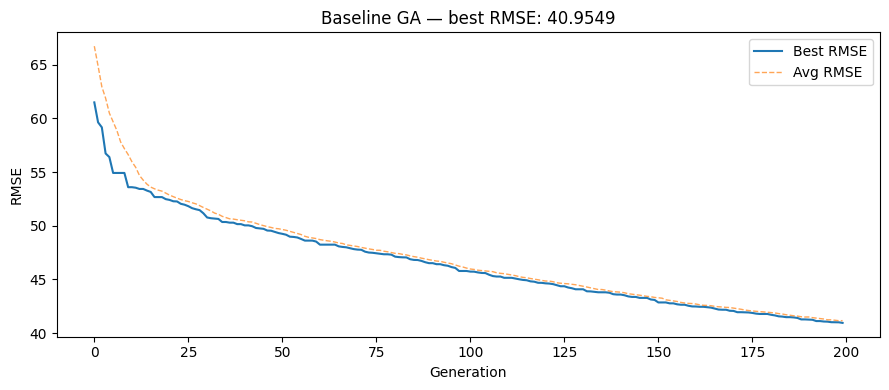

In [4]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

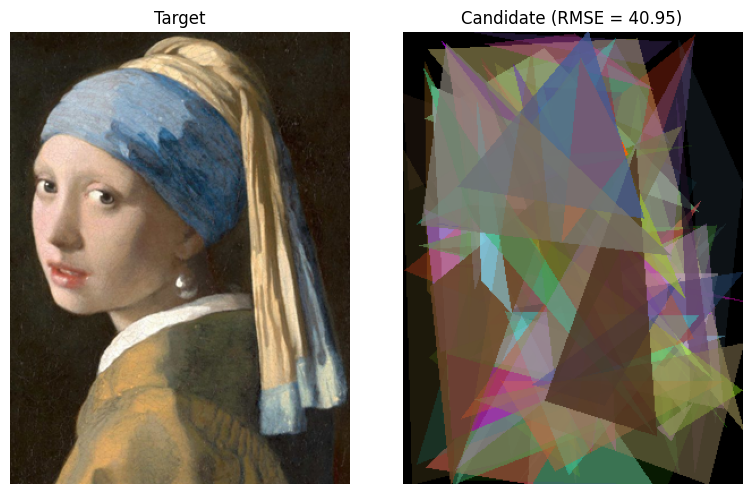

In [5]:
best_sol.show()

# <span id="chapter5" style="color:#89AC76;">5. Genetic Operators</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

This section defines the genetic operators implemented for the triangle-image representation. The next section then compares these alternatives empirically and selects the operators and hyperparameters used in the final run.

### Selection

Selection chooses parents based on fitness. Because this is a minimization problem, lower RMSE corresponds to better fitness.

- **[Roulette-wheel selection](operators/selection.py#L5):** uses inverted RMSE values so lower-error individuals have higher selection probability.
- **[Rank-based selection](operators/selection.py#L20):** assigns probabilities according to sorted rank rather than raw RMSE differences.
- **[Tournament selection](operators/selection.py#L36):** samples a subset of individuals and selects the best one; the tournament size controls selection pressure.
- **[Fitness sharing](operators/new_fitness_sharing.py#L86):** adjusts fitness during selection by penalizing individuals in crowded regions of the genotype space.

### Crossover

Crossover recombines parent genotypes. Since each group of genes defines a complete triangle, most crossover operators preserve triangle boundaries instead of splitting inside a triangle.

- **[One-point crossover](operators/crossover.py#L7):** swaps the suffix of two parents after a randomly chosen triangle boundary.
- **[Two-point crossover](operators/crossover.py#L35):** swaps a middle segment between two triangle-boundary cut points.
- **[Uniform crossover](operators/crossover.py#L72):** independently chooses, for each triangle position, which parent contributes that triangle.
- **[Geometric crossover](operators/crossover.py#L107):** creates real-valued offspring by taking weighted combinations of parent genes and clipping them to valid coordinate and colour ranges.

### Mutation

Mutation introduces new variation by modifying existing individuals. The representation is bounded and mostly continuous, so mutation operators either perturb genes locally or reset parts of the representation.

- **[Gaussian mutation](operators/mutation.py#L6):** adds normally distributed noise to vertex and RGBA genes.
- **[Color-only Gaussian mutation](operators/mutation.py#L61):** changes only RGBA values.
- **[Vertex-only Gaussian mutation](operators/mutation.py#L100):** changes only triangle coordinates.
- **[Per-gene reset mutation](operators/mutation.py#L142):** randomly resets individual genes.
- **[Per-triangle reset mutation](operators/mutation.py#L183):** replaces complete triangles.
- **[Layer-swap mutation](operators/mutation.py#L227):** swaps two triangles in the drawing order, changing occlusion without changing shape or colour.
- **[Geometric mutation](operators/mutation.py#L274):** applies bounded uniform perturbations, following the box-mutation idea for continuous optimization.

# <span id="chapter6" style="color:#89AC76;">6. Statistical Tests</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

This section compares GA operators and hyperparameters using repeated runs. Since GA performance depends on random initialization, selection, crossover, and mutation, decisions are based on distributions of results rather than single executions.

For each configuration, we track the best RMSE over generations and summarize performance using average best fitness with standard-deviation bands. These plots show convergence speed, final quality, and run-to-run stability.

When two configurations are close, we compare their final best RMSE values statistically. We first test normality. If both samples are approximately normal, we use Welch's t-test; otherwise, we use a non-parametric test. Independent runs are compared with the Mann-Whitney U test, while paired runs would use the Wilcoxon signed-rank test. The significance level is set to **alpha = 0.05**.

## <span id="chapter6.1" style="color:#89AC76;">6.1 Selection</span>

In this section, we compare the implemented selection strategies: roulette-wheel selection, rank-based selection, and tournament selection with different tournament sizes.

Selection controls which individuals are chosen as parents and therefore directly affects selection pressure. Low pressure may preserve diversity but slow convergence, while high pressure can accelerate improvement but increase the risk of premature convergence.

Because the problem is a minimization task, roulette-wheel selection uses inverted RMSE values so that lower-error individuals have higher selection probability. Rank-based selection uses the ordering of individuals rather than raw RMSE differences. Tournament selection selects the best individual from a randomly sampled subset, making the tournament size the main control for selection pressure.

The goal of this comparison is to identify a selection method that improves RMSE consistently while maintaining enough diversity for later generations.

In [ ]:
# selection_statistical_comparison = run_ga_statistical_comparison(
#     "selection_function",
#     [
#         roulette_wheel_selection,
#         rank_based_selection,
#         tournament_selection, # default tournament size is 2, # with a population of size 200, this is a selection pressure of 1%
#         lambda p: tournament_selection(p, tournament_size=3), # with a population of size 200, this is a selection pressure of 1.5%
#         lambda p: tournament_selection(p, tournament_size=5), # with a population of size 200, this is a selection pressure of 2.5%
#         lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
#     ]
# )


Starting statistical comparison: 180 GA runs, 1,800,000 total evaluations



Progress: 100%|██████████| 1800000/1800000 [39:46<00:00, 754.17 evaluation/s] 


In [ ]:
# save_statistical_results(
#     selection_statistical_comparison,
#     "results/selection_statistical_comparison.pkl"
# )

In [ ]:
selection_statistical_comparison = load_statistical_results("results/selection_statistical_comparison.pkl")

In [6]:
selection_functions = [
    "Roullete wheel",
    "Rank based selected",
    "Tournament selection (2)",
    "Tournament selection (3)",
    "Tournament selection (5)",
    "Tournament selection (10)"
]

plot_statistical_comparison_interactive(
    selection_statistical_comparison,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

based on the results from this statistical comparison, let's try even lower selection pressures in tournament selection

In [ ]:
# selection_statistical_comparison2 = run_ga_statistical_comparison(
#     "selection_function",
#     [
#         # lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
#         lambda p: tournament_selection(p, tournament_size=15), # with a population of size 200, this is a selection pressure of 7.5%
#         lambda p: tournament_selection(p, tournament_size=20), # with a population of size 200, this is a selection pressure of 10%
#         lambda p: tournament_selection(p, tournament_size=30), # with a population of size 200, this is a selection pressure of 15%
#     ]
# )


Starting statistical comparison: 90 GA runs, 900,000 total evaluations



Progress: 100%|██████████| 900000/900000 [20:35<00:00, 728.66 evaluation/s] 


In [ ]:
# save_statistical_results(
#     selection_statistical_comparison2,
#     "results/selection_statistical_comparison2.pkl"
# )

In [ ]:
selection_statistical_comparison2 = load_statistical_results("results/selection_statistical_comparison2.pkl")

In [19]:
selection_functions = [
    "Tournament selection (15)",
    "Tournament selection (20)",
    "Tournament selection (30)",
]

plot_statistical_comparison_interactive(
    selection_statistical_comparison2,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

All of the values seem to be statistically equivalent, with all of them being really close together and inside the standard deviations of eachother

we should now do statistical tests to choose the best option

## <span id="chapter6.2" style="color:#89AC76;">6.2. Crossover</span>

try here all of the crossover operators and do statistical tests to compare between them

preciso de corrigir o geometric crossover para dar apenas um offspring - pelos vistos pode haver diferença em retornar só um ou dois, pois afeta a diversidade da população

In [23]:
crossover_statistical_comparison = run_ga_statistical_comparison(
    "crossover_function",
    [
        one_point_crossover,
        two_point_crossover,
        uniform_crossover,
        geometric_crossover
    ]
)


Starting statistical comparison: 120 GA runs, 1,200,000 total evaluations



Progress: 100%|██████████| 1200000/1200000 [28:40<00:00, 697.62 evaluation/s]


In [24]:
save_statistical_results(
    crossover_statistical_comparison,
    "results/crossover_statistical_comparison.pkl"
)

In [ ]:
crossover_statistical_comparison = load_statistical_results("results/crossover_statistical_comparison.pkl")

In [25]:
crossover_functions = [
    "One point",
    "Two point",
    "Uniform",
    "Geometric"
]

plot_statistical_comparison_interactive(
    crossover_statistical_comparison,
    labels=crossover_functions,
    title="Crossover Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [5]:
run_statistical_test(
    crossover_statistical_comparison[one_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="One point",
    name_b="Uniform",
    paired=False
)

One point normality p-value: 0.5982
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

One point mean final RMSE: 39.6114
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


In [6]:
run_statistical_test(
    crossover_statistical_comparison[two_point_crossover]["best_per_run"],
    crossover_statistical_comparison[uniform_crossover]["best_per_run"],
    name_a="Two point",
    name_b="Uniform",
    paired=False
)

Two point normality p-value: 0.0644
Uniform normality p-value: 0.3007

Welch t-test
p-value: 0.0000

Two point mean final RMSE: 38.7940
Uniform mean final RMSE: 35.4099
Difference is statistically significant.


now we test for the best crossover rate

In [ ]:
# crossover_rate_statistical_comparison = run_ga_statistical_comparison(
#     "crossover_rate",
#     [
#         0.90,
#         0.80,
#         0.70,
#         0.50,
#         0.30
#     ],
#     fixed_params={
#         "crossover_function": uniform_crossover
#     }
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:13<00:00, 709.80 evaluation/s]


In [ ]:
# save_statistical_results(
#     crossover_rate_statistical_comparison,
#     "results/crossover_rate_statistical_comparison.pkl"
# )

In [ ]:
crossover_rate_statistical_comparison = load_statistical_results("results/crossover_rate_statistical_comparison.pkl")

In [12]:
crossover_rates = [
    "0.90",
    "0.80",
    "0.70",
    "0.50",
    "0.30"
]

plot_statistical_comparison_interactive(
    crossover_rate_statistical_comparison,
    labels=crossover_rates,
    title="Crossover Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

## <span id="chapter6.3" style="color:#89AC76;">6.3. Mutation</span>

### <span id="chapter6.3.1" style="color:#89AC76;">6.3.1. Mutation operator</span>

In [ ]:
# mutation_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_function",
#     [
#         triangle_gaussian_mutation,
#         triangle_gaussian_color_mutation,
#         triangle_gaussian_vertex_mutation,
#         triangle_reset_gene_mutation,
#         triangle_reset_mutation,
#         triangle_layer_swap_mutation,
#         geometric_mutation
#     ]
# )


Starting statistical comparison: 210 GA runs, 2,100,000 total evaluations



Progress: 100%|██████████| 2100000/2100000 [44:57<00:00, 778.44 evaluation/s]


In [ ]:
# save_statistical_results(
#     mutation_statistical_comparison,
#     "results/mutation_statistical_comparison.pkl"
# )

In [ ]:
mutation_statistical_comparison = load_statistical_results("results/mutation_statistical_comparison.pkl")

In [9]:
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap",
    "Geometric"
]

plot_statistical_comparison_interactive(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

### <span id="chapter6.3.2" style="color:#89AC76;">6.3.2. Mutation rate</span>

Now we need to select the best mutation rate

In [ ]:
# mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate",
#     [
#         0.50,
#         0.20,
#         0.10,
#         0.05,
#         0.02,
#         0.01
#     ]
# )


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [45:15<00:00, 13.26 gen/s] 


In [ ]:
# save_statistical_results(
#     mutation_rate_statistical_comparison,
#     "results/mutation_rate_statistical_comparison.pkl"
# )

In [3]:
mutation_rate_statistical_comparison = load_statistical_results("results/mutation_rate_statistical_comparison.pkl")

In [7]:
mutation_rates = [
    "0.50",
    "0.20",
    "0.10",
    "0.05",
    "0.02",
    "0.01"
]

plot_statistical_comparison_interactive(
    mutation_rate_statistical_comparison,
    labels=mutation_rates,
    title="Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [9]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.01]["best_per_run"],
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    name_a="0.01",
    name_b="0.02",
    paired=False
)

0.01 normality p-value: 0.2514
0.02 normality p-value: 0.4021

Welch t-test
p-value: 0.0013

0.01 mean final RMSE: 40.2189
0.02 mean final RMSE: 39.0638
Difference is statistically significant.


In [11]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.02]["best_per_run"],
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    name_a="0.02",
    name_b="0.05",
    paired=False
)

0.02 normality p-value: 0.4021
0.05 normality p-value: 0.9225

Welch t-test
p-value: 0.0000

0.02 mean final RMSE: 39.0638
0.05 mean final RMSE: 37.0871
Difference is statistically significant.


In [22]:
run_statistical_test(
    mutation_rate_statistical_comparison[0.05]["best_per_run"],
    mutation_rate_statistical_comparison[0.10]["best_per_run"],
    name_a="0.05",
    name_b="0.10",
    paired=False
)

0.05 normality p-value: 0.9225
0.10 normality p-value: 0.0003

Mann-Whitney U / Wilcoxon rank-sum test
p-value: 0.0007

0.05 mean final RMSE: 37.0871
0.10 mean final RMSE: 36.1952
Difference is statistically significant.


### <span id="chapter6.3.3" style="color:#89AC76;">6.3.3. Gaussian mutation sigma</span>

gaussian mutation has two additional parameters we can tune, sigma_vertex and sigma_color

#### Sigma vertex

In [ ]:
# sigma_vertex_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_vertex",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [32:31<00:00, 768.82 evaluation/s]


In [ ]:
# save_statistical_results(
#     sigma_vertex_statistical_comparison,
#     "results/sigma_vertex_statistical_comparison.pkl"
# )

In [6]:
sigma_vertex_statistical_comparison = load_statistical_results("results/sigma_vertex_statistical_comparison.pkl")

In [7]:
sigma_vertex = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_vertex_statistical_comparison,
    labels=sigma_vertex,
    title="Mutation Sigma Vertex Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [8]:
run_statistical_test(
    sigma_vertex_statistical_comparison[2]["best_per_run"],
    sigma_vertex_statistical_comparison[5]["best_per_run"],
    "2",
    "5",
    paired=False
)

2 normality p-value: 0.2538
5 normality p-value: 0.4879

Welch t-test
p-value: 0.9204

2 mean final RMSE: 39.5895
5 mean final RMSE: 39.6208
No statistically significant difference detected.


#### Sigma color

In [ ]:
# sigma_color_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_color",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [38:01<00:00, 657.33 evaluation/s]


In [ ]:
# save_statistical_results(
#     sigma_color_statistical_comparison,
#     "results/sigma_color_statistical_comparison.pkl"
# )

In [ ]:
sigma_color_statistical_comparison = load_statistical_results("results/sigma_color_statistical_comparison.pkl")

In [8]:
sigma_color = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_color_statistical_comparison,
    labels=sigma_color,
    title="Mutation Sigma Color Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [9]:
run_statistical_test(
    sigma_color_statistical_comparison[10]["best_per_run"],
    sigma_color_statistical_comparison[20]["best_per_run"],
    "10",
    "20",
    paired=False
)

10 normality p-value: 0.4073
20 normality p-value: 0.5641

Welch t-test
p-value: 0.0000

10 mean final RMSE: 39.8364
20 mean final RMSE: 38.0604
Difference is statistically significant.


In [10]:
run_statistical_test(
    sigma_color_statistical_comparison[20]["best_per_run"],
    sigma_color_statistical_comparison[50]["best_per_run"],
    "20",
    "50",
    paired=False
)

20 normality p-value: 0.5641
50 normality p-value: 0.4173

Welch t-test
p-value: 0.0778

20 mean final RMSE: 38.0604
50 mean final RMSE: 38.5659
No statistically significant difference detected.


### <span id="chapter6.3.4" style="color:#89AC76;">6.3.4. Adaptive mutation rate</span>

Now we will test strategies for adapting mutation rates:
- Mutation rate decay
- Self-adaptive mutation rate (gene)

#### Mutation rate decay

In [ ]:
# mutation_rate_decay_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate_decay",
#     [
#         None,
#         0.1,
#         0.01,
#         0.001,
#         0.0001,
#         0.00001
#     ],
#     fixed_params={
#         "mutation_rate": 0.10
#     }
# )


Starting statistical comparison: 180 GA runs, 1,800,000 total evaluations



Progress: 100%|██████████| 1800000/1800000 [47:15<00:00, 634.74 evaluation/s]


In [ ]:
# save_statistical_results(
#     mutation_rate_decay_statistical_comparison,
#     "results/mutation_rate_decay_statistical_comparison.pkl"
# )

In [ ]:
mutation_rate_decay_statistical_comparison = load_statistical_results("results/mutation_rate_decay_statistical_comparison.pkl")

In [31]:
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison_interactive(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

#### Adaptive mutation rate

In [ ]:
# adaptive_mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "solution_class",
#     [
#         TriangleSolution,
#         AdaptiveMutationRateTriangleSolution
#     ],
#     eval_budget=25_000 # 50 individuals x 500 generations
# )


Starting statistical comparison: 60 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:43<00:00, 699.63 evaluation/s]


In [ ]:
# save_statistical_results(
#     adaptive_mutation_rate_statistical_comparison,
#     "results/adaptive_mutation_rate_statistical_comparison.pkl"
# )

In [ ]:
adaptive_mutation_rate_statistical_comparison = load_statistical_results("results/adaptive_mutation_rate_statistical_comparison.pkl")

In [ ]:
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison_interactive(
    adaptive_mutation_rate_statistical_comparison,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
run_statistical_test(
    adaptive_mutation_rate_statistical_comparison[TriangleSolution]["best_per_run"],
    sigma_color_statistical_comparison[AdaptiveMutationRateTriangleSolution]["best_per_run"],
    "Static mutation rate",
    "Self-adaptive mutation rate",
    paired=False
)

## <span id="chapter6.4" style="color:#89AC76;">6.4. Elitism</span>

In [ ]:
# elitism_n_statistical_comparison = run_ga_statistical_comparison(
#     "elitism_n",
#     [
#         2,
#         5,
#         10,
#         20
#     ]
# )


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [21:43<00:00, 18.42 gen/s]


In [ ]:
# save_statistical_results(
#     elitism_n_statistical_comparison,
#     "results/elitism_n_statistical_comparison.pkl"
# )

In [15]:
elitism_n_statistical_comparison = load_statistical_results("results/elitism_n_statistical_comparison.pkl")

In [16]:
elitism_n = [
    "2",
    "5",
    "10",
    "20"
]

plot_statistical_comparison_interactive(
    elitism_n_statistical_comparison,
    labels=elitism_n,
    title="Elitism Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

add statistical tests

## <span id="chapter6.5" style="color:#89AC76;">6.5. Population size</span>

this test is not fair, as the bigger the population, the more evaluations were done

but it may be useful to check which is the biggest population size that still makes sense to use while not being too slow

For population-size comparisons, performance should be interpreted against cumulative fitness evaluations rather than generations, since larger populations perform more evaluations per generation.

In [17]:
population_size_statistical_comparison = run_ga_statistical_comparison(
    "population_size",
    [
        200,
        400,
        800,
        1500
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [6:07:31<00:00,  1.09 gen/s]  


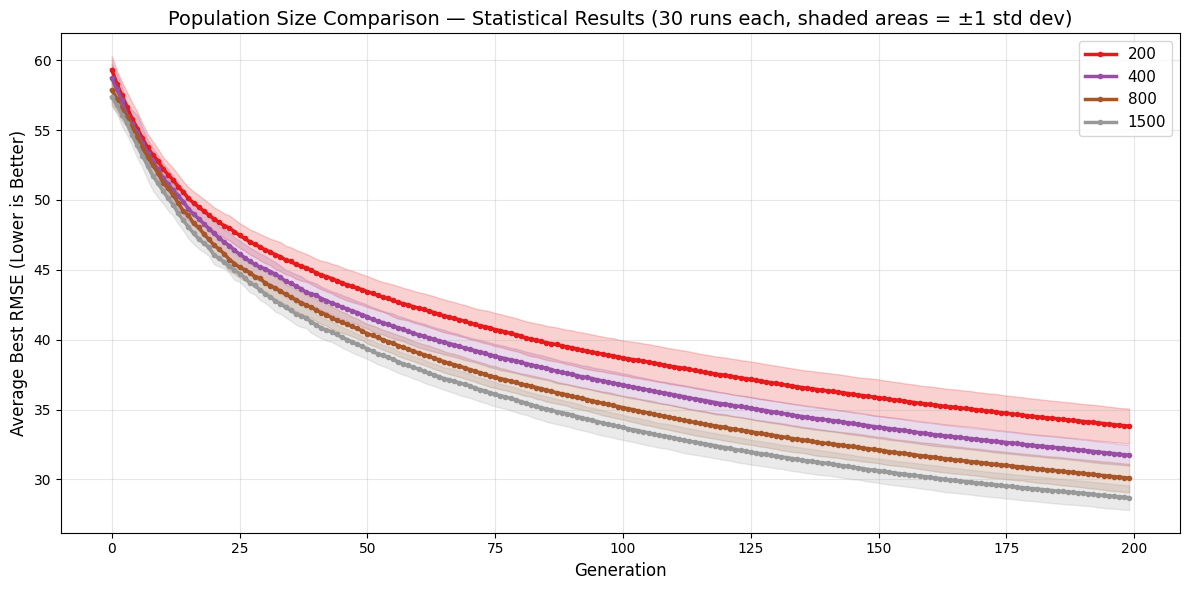

In [18]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
# population_size_statistical_comparison = run_ga_statistical_comparison(
#     "population_size",
#     [
#         200,
#         400,
#         800,
#         1500
#     ],
#     eval_budget=12_000 # 12 000 is the least common multiple between all of the options
# )


Starting statistical comparison: 120 GA runs, 1,440,000 total evaluations



Progress: 100%|██████████| 1440000/1440000 [35:51<00:00, 669.25 evaluation/s]


In [ ]:
# save_statistical_results(
#     population_size_statistical_comparison,
#     "results/population_size_statistical_comparison.pkl"
# )

In [ ]:
population_size_statistical_comparison = load_statistical_results("results/population_size_statistical_comparison.pkl")

In [11]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison_interactive(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

add statistical tests

# <span id="chapter7" style="color:#89AC76;">7. Final GA Run </span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In the "Statistical Tests" section we have tested statistically what operators and parameters to use and we have selected these ones:
- 200 population size
- Tournament Selection with size 10
- Uniform crossover
- 0.9 crossover rate
- Full Gaussian mutation, with sigma_vertex 5 and sigma_color 20
- 0.05 mutation rate
- Elite size 2
- No Mutation rate decay

In [49]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.05,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2366 | avg RMSE: 63.9467 | mut rate: 0.05000
Gen   50 | best RMSE: 35.0225 | avg RMSE: 35.4705 | mut rate: 0.05000
Gen  100 | best RMSE: 31.1546 | avg RMSE: 31.5197 | mut rate: 0.05000
Gen  150 | best RMSE: 29.5126 | avg RMSE: 29.8968 | mut rate: 0.05000
Gen  200 | best RMSE: 28.6467 | avg RMSE: 28.9708 | mut rate: 0.05000
Gen  250 | best RMSE: 27.6373 | avg RMSE: 28.0401 | mut rate: 0.05000
Gen  300 | best RMSE: 26.9109 | avg RMSE: 27.3115 | mut rate: 0.05000
Gen  350 | best RMSE: 26.4646 | avg RMSE: 26.9079 | mut rate: 0.05000
Gen  400 | best RMSE: 26.1257 | avg RMSE: 26.5381 | mut rate: 0.05000
Gen  450 | best RMSE: 25.8444 | avg RMSE: 26.2806 | mut rate: 0.05000
Gen  500 | best RMSE: 25.6701 | avg RMSE: 26.0775 | mut rate: 0.05000
Gen  550 | best RMSE: 25.5288 | avg RMSE: 25.9416 | mut rate: 0.05000
Gen  600 | best RMSE: 25.3142 | avg RMSE: 25.7271 | mut rate: 0.05000
Gen  650 | best RMSE: 25.1692 | avg RMSE: 25.5949 | mut rate: 0.05000
Gen  700 | best RMSE

KeyboardInterrupt: 

--- old run

In [48]:
0.05 / (1 + 0.0001)**8000

0.02246734682185626

In [ ]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.10,
    mutation_rate_decay=0.0001,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 59.4729 | avg RMSE: 64.1930 | mut rate: 0.10000
Gen   50 | best RMSE: 33.7682 | avg RMSE: 34.5277 | mut rate: 0.09950
Gen  100 | best RMSE: 29.0319 | avg RMSE: 29.7918 | mut rate: 0.09901
Gen  150 | best RMSE: 27.7359 | avg RMSE: 28.4642 | mut rate: 0.09851
Gen  200 | best RMSE: 26.6532 | avg RMSE: 27.4683 | mut rate: 0.09802
Gen  250 | best RMSE: 25.6681 | avg RMSE: 26.5019 | mut rate: 0.09753
Gen  300 | best RMSE: 24.8454 | avg RMSE: 25.8269 | mut rate: 0.09704
Gen  350 | best RMSE: 24.6374 | avg RMSE: 25.6190 | mut rate: 0.09656
Gen  400 | best RMSE: 24.3062 | avg RMSE: 25.3358 | mut rate: 0.09608
Gen  450 | best RMSE: 23.7535 | avg RMSE: 24.7620 | mut rate: 0.09560
Gen  500 | best RMSE: 23.5085 | avg RMSE: 24.5291 | mut rate: 0.09512
Gen  550 | best RMSE: 23.3894 | avg RMSE: 24.4180 | mut rate: 0.09465
Gen  600 | best RMSE: 23.3305 | avg RMSE: 24.3181 | mut rate: 0.09418
Gen  650 | best RMSE: 23.2259 | avg RMSE: 24.2622 | mut rate: 0.09371
Gen  700 | best RMSE

KeyboardInterrupt: 

--- old run

In [ ]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2414 | avg RMSE: 68.5261 | mut rate: 0.01000
Gen   50 | best RMSE: 32.6811 | avg RMSE: 33.0376 | mut rate: 0.01000
Gen  100 | best RMSE: 28.4080 | avg RMSE: 28.5723 | mut rate: 0.01000
Gen  150 | best RMSE: 26.3321 | avg RMSE: 26.4435 | mut rate: 0.01000
Gen  200 | best RMSE: 25.0181 | avg RMSE: 25.1214 | mut rate: 0.01000
Gen  250 | best RMSE: 24.0273 | avg RMSE: 24.1036 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2857 | avg RMSE: 23.3618 | mut rate: 0.01000
Gen  350 | best RMSE: 22.6252 | avg RMSE: 22.7005 | mut rate: 0.01000
Gen  400 | best RMSE: 22.1101 | avg RMSE: 22.1982 | mut rate: 0.01000
Gen  450 | best RMSE: 21.7268 | avg RMSE: 21.8015 | mut rate: 0.01000
Gen  500 | best RMSE: 21.3595 | avg RMSE: 21.4520 | mut rate: 0.01000
Gen  550 | best RMSE: 21.1173 | avg RMSE: 21.2031 | mut rate: 0.01000
Gen  600 | best RMSE: 20.7939 | avg RMSE: 20.8765 | mut rate: 0.01000
Gen  650 | best RMSE: 20.5164 | avg RMSE: 20.6087 | mut rate: 0.01000
Gen  700 | best RMSE

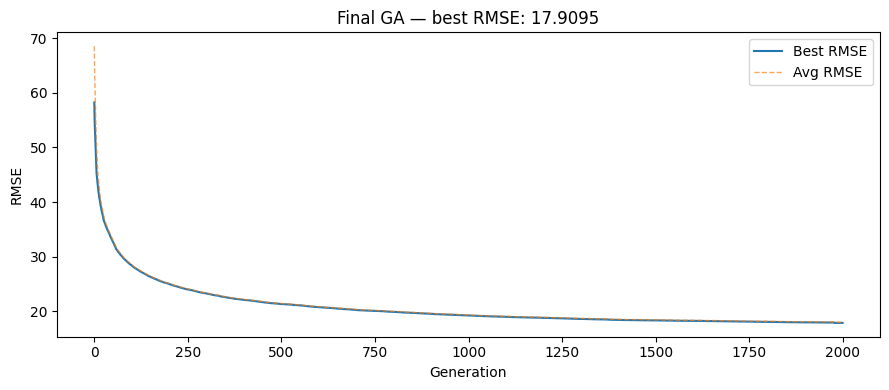

In [22]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Final GA — best RMSE: {history[-1]:.4f}",
)

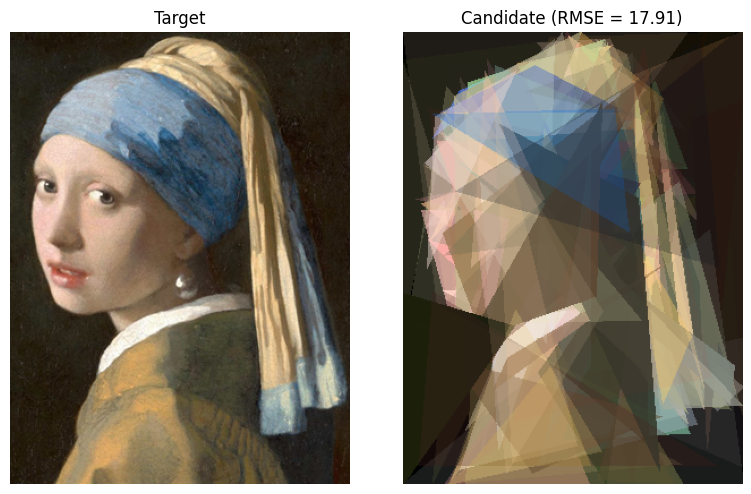

In [20]:
best_sol.show()

# <span id="chapter8" style="color:#89AC76;">8. Fitness Sharing</span>

In [ ]:
selector_test1 = AutomaticFitnessSharingSelection(
    sigma_share=25.0,
    alpha=1.0,
    method = 'tournament',
    tournament_size=5,
)

In [ ]:
diversity_log = []

def diversity_callback(gen, population):
    if gen % 10 == 0:   # every 10 gens to keep overhead low
        diversity_log.append(
            {'gen': gen, **population_diversity_report(population)}
        )

In [ ]:
selector_test2 = AdvancedFitnessSharingSelection(
    sigma_share=0.05, # was 0.15 — tighter niches, less aggressive penalisation
    alpha=1.0,
    tournament_size=5,
)

In [ ]:
VERMEER_SUPER_PARAMS = dict(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=selector_test2,
    generation_callback=GenerationCounterCallback(selector_test2),
    crossover_function=uniform_crossover,
    mutation_function=partial(
        triangle_gaussian_mutation,
        sigma_vertex=15,
        sigma_colour=15,
    ),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2,
    n_jobs=-1,
    verbose=True,
    verbose_every=50,
)

best_sharing, hist_sharing, avg_hist_sharing = genetic_algorithm(**VERMEER_SUPER_PARAMS)

print("-" * 40)
print(f"Best RMSE: {get_fitness(best_sharing):.4f}")


Gen    0 | best RMSE: 58.5873 | avg RMSE: 68.4050 | mut rate: 0.01000
Gen   50 | best RMSE: 32.9923 | avg RMSE: 33.5796 | mut rate: 0.01000
Gen  100 | best RMSE: 28.5885 | avg RMSE: 28.8348 | mut rate: 0.01000
Gen  150 | best RMSE: 26.6630 | avg RMSE: 26.9731 | mut rate: 0.01000
Gen  200 | best RMSE: 25.6382 | avg RMSE: 25.8953 | mut rate: 0.01000
Gen  250 | best RMSE: 24.5973 | avg RMSE: 24.8809 | mut rate: 0.01000
Gen  300 | best RMSE: 24.0464 | avg RMSE: 24.2687 | mut rate: 0.01000
Gen  350 | best RMSE: 23.7293 | avg RMSE: 23.9533 | mut rate: 0.01000
Gen  400 | best RMSE: 23.4668 | avg RMSE: 23.6709 | mut rate: 0.01000
Gen  450 | best RMSE: 23.1850 | avg RMSE: 23.4513 | mut rate: 0.01000
Gen  500 | best RMSE: 22.8442 | avg RMSE: 23.0959 | mut rate: 0.01000
Gen  550 | best RMSE: 22.6074 | avg RMSE: 22.8607 | mut rate: 0.01000
Gen  600 | best RMSE: 22.4778 | avg RMSE: 22.7495 | mut rate: 0.01000
Gen  650 | best RMSE: 22.3346 | avg RMSE: 22.5941 | mut rate: 0.01000
Gen  700 | best RMSE

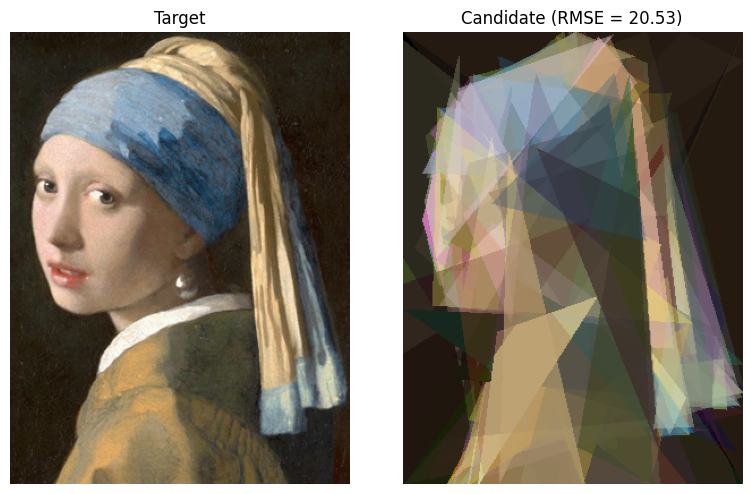

In [ ]:
best_sharing.show()

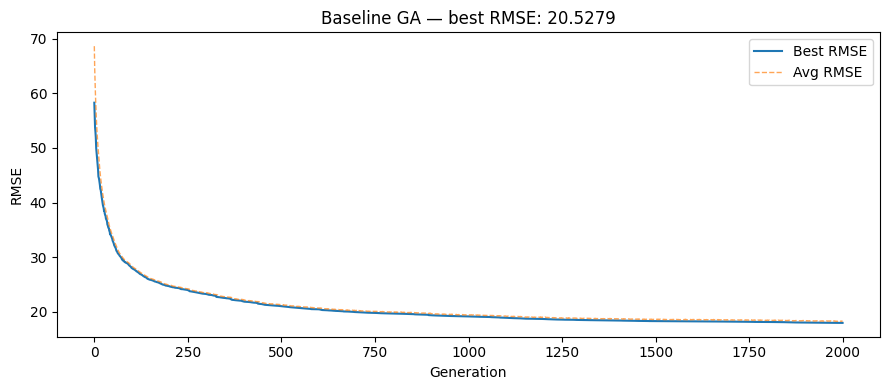

In [ ]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {hist_sharing[-1]:.4f}",
)

# <span id="chapter9" style="color:#89AC76;">9. Hill Climbing for Local Search</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [ ]:
ga_rmse_before_hc = get_fitness(best_sol) #from test 1

""" PREVIOUS RESULT - 1.92% IMPROVEMENT:

best_polished_solution, hc_log, hc_evals = hill_climbing(
    solution=best_sol, # best individual from the GA
    max_iterations=30,
    delta_vertex=12.0,
    delta_colour=10.0,
    decay_factor=0.6,
    min_delta=0.1,
    trials_per_iteration=1,
    verbose=True,
)

print(f"\nGA final RMSE  : {ga_rmse_before_hc:.4f}")
print(f"HC final RMSE  : {best_polished_solution.fitness():.4f}")
improvement = ga_rmse_before_hc - best_polished_solution.fitness()
print(f"Improvement    : {improvement:.4f}  ({improvement / ga_rmse_before_hc * 100:.2f} %)")
print(f"Evaluations    : {hc_evals:,}")
"""

best_polished_solution, hc_log, hc_evals = hill_climbing( # 3.71%
    solution=best_sol,
    max_iterations=100, # still improving, give it more budget
    delta_vertex=7.0, # start where it actually worked, skip the wasted iter 1
    delta_colour=6.0, # same reasoning
    decay_factor=0.7, # slower decay, stays at productive scale longer
    min_delta=0.05, # allow finer refinement at the end
    trials_per_iteration=2,# 2 perturbations per triangle per pass
    verbose=True,
)

print(f"\nGA final RMSE : {ga_rmse_before_hc:.4f}")
print(f"HC final RMSE : {best_polished_solution.fitness():.4f}")
improvement = ga_rmse_before_hc - best_polished_solution.fitness()
print(f"Improvement : {improvement:.4f}  ({improvement / ga_rmse_before_hc * 100:.2f} %)")
print(f"Evaluations : {hc_evals:,}")


Hill Climbing start — RMSE: 17.9780 | delta_v=7.00, delta_c=6.00
  Iter   1 | RMSE: 17.9656 | improvements:   10 | delta_v=7.000, delta_c=6.000
  Iter   2 | RMSE: 17.9556 | improvements:    9 | delta_v=7.000, delta_c=6.000
  Iter   3 | RMSE: 17.9419 | improvements:   10 | delta_v=7.000, delta_c=6.000
  Iter   4 | RMSE: 17.9334 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   5 | RMSE: 17.9312 | improvements:    1 | delta_v=7.000, delta_c=6.000
  Iter   6 | RMSE: 17.9152 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   7 | RMSE: 17.9100 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   8 | RMSE: 17.8966 | improvements:    1 | delta_v=7.000, delta_c=6.000
  Iter   9 | RMSE: 17.8811 | improvements:    8 | delta_v=7.000, delta_c=6.000
  Iter  10 | RMSE: 17.8672 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter  11 | RMSE: 17.8539 | improvements:    5 | delta_v=7.000, delta_c=6.000
  Iter  12 | RMSE: 17.8520 | improvements:    3 | delta_v=7.000, d

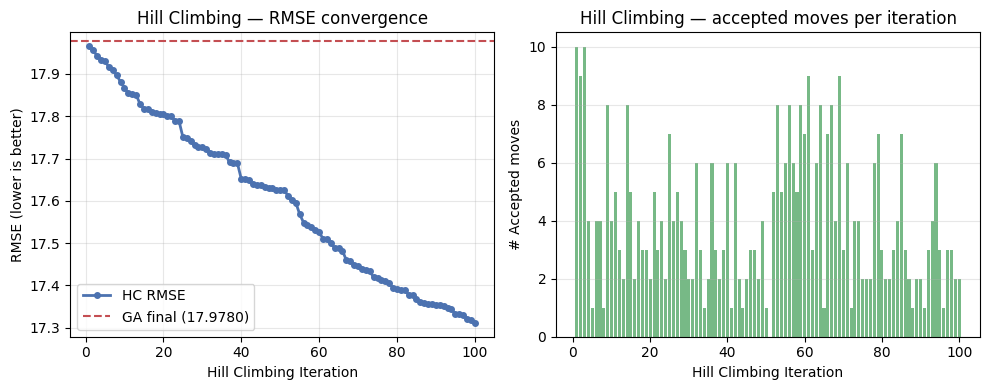

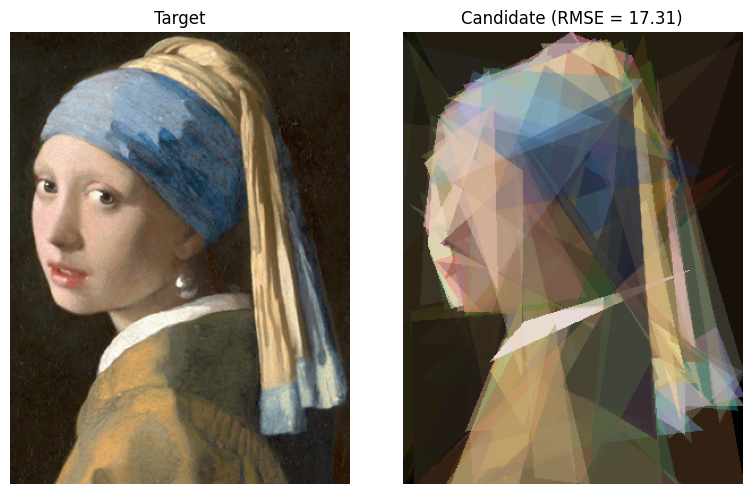

In [ ]:
# Visual comparison
plot_hill_climbing_log(hc_log, ga_final_rmse=ga_rmse_before_hc)
best_polished_solution.show()

# <span id="chapter10" style="color:#89AC76;">10. Best Candidate vs. Target </span>

o que fazer aqui? talvez esta secção não faça muito sentido

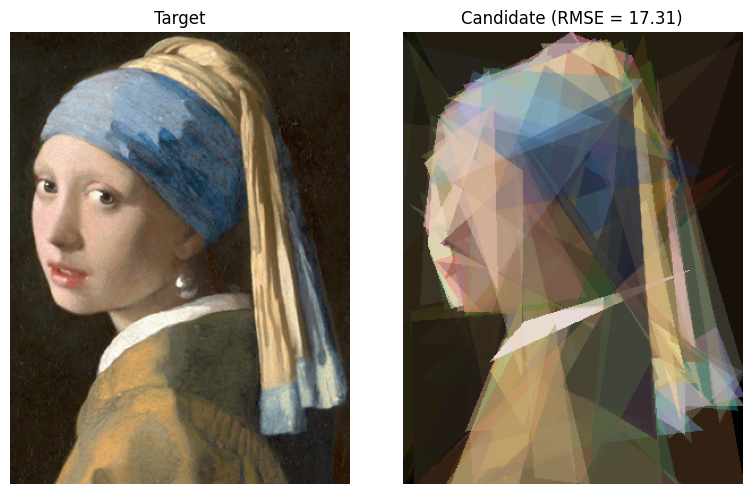

In [ ]:
best_polished_solution.show()

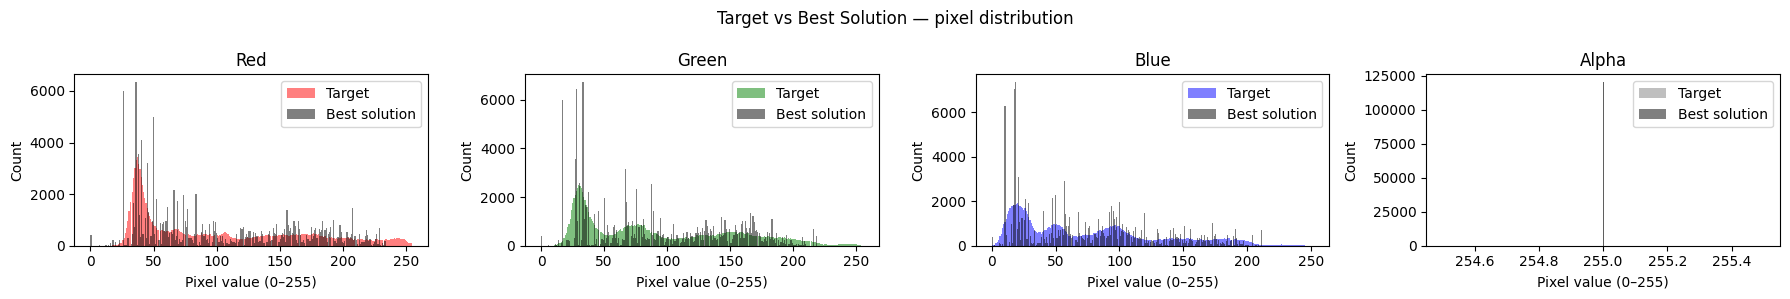

In [ ]:
#### Does this make sense???


rendered_arr = np.array(best_sol.get_image())

fig, axes = plt.subplots(1, 4, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:,:,i].ravel(),   bins=256, color=col,   alpha=0.5, label='Target')
    axes[i].hist(rendered_arr[:,:,i].ravel(), bins=256, color='black', alpha=0.5, label='Best solution')
    axes[i].set_title(ch)
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')
    axes[i].legend()

plt.suptitle('Target vs Best Solution — pixel distribution')
plt.tight_layout()
plt.show()

# <span id="chapter11" style="color:#89AC76;">11. Save Best Result</span>

<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [21]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

Saved best candidate to: best_result.png
